# Numerical Computation of Action-variables
1. Mesh of the energy
2. Identification of the turning points for an orbit (Newton root)
3. Test the method for one orbit:
    - Define the change of varible $u \rightarrow q$
    - Compute the integral $J$ (using a mesh on $u$)
    - Compute the integral $\Phi$ <i>(to be continued...)</i>
    - Test the convergence
4. Label the orbits
5. Group the orbits for each separatrix regions
6. Compute $J$, and $\omega$

[1] Berg and Warnock


In [370]:
import numpy as np
from matplotlib import pyplot as plt

# The Hamiltonian

In [371]:
def V(q):
    return q**4/2 - q**2 + 0.5

def p(q, H):
    return np.real(np.sqrt(2*H - 2*V(q), dtype=complex))

### 1. Mesh grid for $H$: $H_i$

In [372]:
H0 = 0
H1 = 1
Ni = 100

H = np.linspace(H0, H1, Ni)

### 2. Turning points $q_0$ and $q_1$

In [373]:
def Newton_root(f, q_0, tol=1e-6, max_iter=100):
    q = q_0
    for i in range(max_iter):
        f_q = f(q)
        f_prime_q = (f(q + tol) - f(q - tol)) / (2*tol)  # Numerical derivative
        if abs(f_prime_q) < tol:
            # if the derivative is small, we are close to a stationary point
            # Let's find the max/min and see if it is a root (or close enought to it)
            f_prime = lambda q: (f(q + tol) - f(q - tol)) / (2*tol)
            q_new = Newton_root(f_prime, q, tol=tol, max_iter=max_iter)
            if abs(q_new - q) < tol:
                if abs(f(q_new)) < tol:
                    return q_new
                else:
                    return None
        q_new = q - f_q / f_prime_q
        if abs(q_new - q) < tol:
            return q_new
        q = q_new
    raise ValueError("Newton's method did not converge within the maximum number of iterations.")

def root_guess(f, qmin=-5, qmax=5, Nq=111):
    # sample [qmin, qmax] in many points
    # if |f(xi)|<|f(x{i-1})|, |f(x{i+1})|, xi is a good guess
    # Return: np.array of dim n (number of roots)
    qj = np.linspace(qmin, qmax, Nq)
    fj = f(qj)
    root=[]
    i=0
    for i in range(1, Nq-1):
        if np.abs(fj[i])<np.abs(fj[i-1]) and np.abs(fj[i])<np.abs(fj[i+1]):
            root.append(qj[i])
    return np.array(root)

In [374]:
def turning_points(V, H,qmin=-5, qmax=5, Nq=111):
    q_root = []
    # find the roots for each energy values
    for i in range(0, len(H)):
        f = lambda q: 2*H[i] - 2*V(q)
        q_root.append(root_guess(f, qmin, qmax, Nq))
        # find the root with newton
        for j in range(0, len(q_root[i])):
            q_root[i][j]  = Newton_root(f, q_root[i][j])
        q_root[i] =  q_root[i][~np.isnan(q_root[i])]  # Remove the root if it is not valid
    return q_root


In [375]:
root = turning_points(V, H)

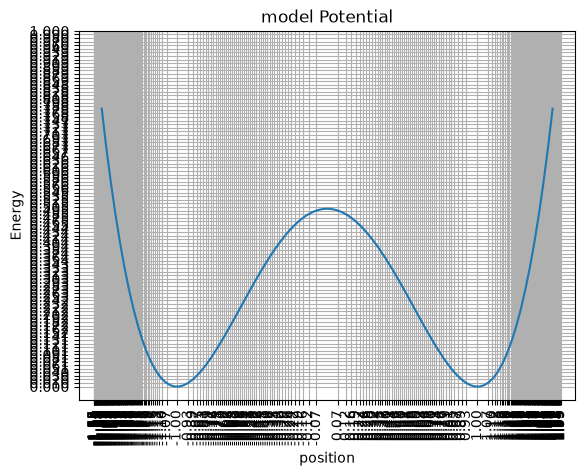

In [376]:
x = np.linspace(-1.5, 1.5, 100)
plt.plot(x, V(x))
plt.title('model Potential')
plt.xlabel('position')
plt.ylabel('Energy')
plt.grid()
plt.yticks(H)
xtic = np.sort(np.concatenate(root))
plt.xticks(xtic, labels=[f'{x:.2f}' for x in xtic], rotation=90)
plt.show()

### 3. Test on a case orbit

In [9]:
i=4


- mesh on $u$

In [10]:
Nu = 101

uj = np.linspace(0, np.pi, Nu)

- change of variable $q \rightarrow u$

In [11]:
def q(u, q0, q1):
    return q0/2*(1+np.cos(u)) + q1/2*(1-np.cos(u))

def u(q, q0, q1):
    return np.arccos((q0+q1-2*q)/(q1-q0))

In [ ]:
qj = q(uj,root[i][0], root[i][1])
pj = p(qj, H[i])

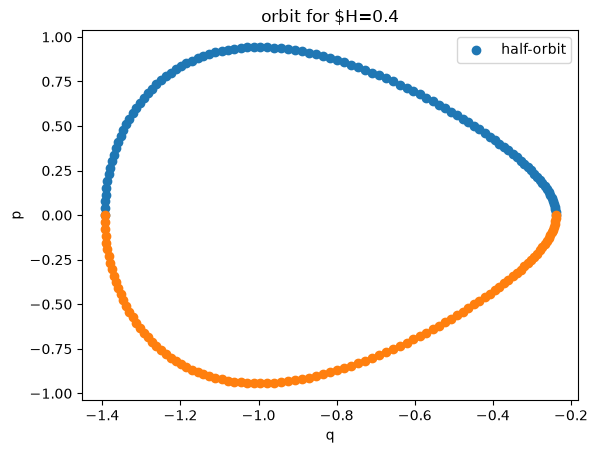

In [13]:
plt.scatter(qj, pj, label='half-orbit')
plt.scatter(qj, -pj)
plt.title('orbit for $H={:.1f}'.format(H[i]))
plt.xlabel('q')
plt.ylabel('p')
plt.legend()
plt.show()

- Computation of $J$ and $\Phi$ with Simpson method

- Computation of $J$ with Simpson method

In [14]:
def simpson(y, dx):
    integral = dx/3*(y[0] + y[len(y)-1])
    for i in range(1, int((len(y)-1)/2)):
        integral = integral + 4*dx/3* y[2*i - 1]
    for i in range(1, int((len(y)-1)/2-1)):
        integral = integral + 2*dx/3*y[2*i]
    return integral

In [15]:
du = uj[1]-uj[0]
integrand_J = np.sin(uj)*pj

J = 1/np.pi*(root[i][1]-root[i][0])/2*simpson(integrand_J,du)
print(" $J$ ",J)

 $J$  0.2538642267620292


- Computation of $\Phi$

<i> Test Richardons extrapolation to see if the integrand is converging.

<u> Note</u>: the integral for $\Phi$ is diverging at turning points </i>

In [16]:
from math import nan

# extrapolation for limit

integrand_Phi =  np.sin(uj)/pj

# use the limit instead of the function where the integrand diverges
ind = np.where(pj==0)[0]
print('problematic points', len(ind))
lim = []
 
for j, index in enumerate(ind):  
    D = np.zeros((5,5))
    f = lambda x: np.sin(x)/p(q(x,root[i][0], root[i][1]), H[i])
    for n in range(0,5):
        D[n,0] = (f(uj[index] + du/2**n)-f(uj[index] - du/2**n))/(du/2**(n))
        for k in range(0,n):
            D[n,k+1] = D[n,k] + (D[n,k]-D[n-1,k])/(4**k-1)
    # print(D)
    if lim == nan :
        print('nan')
        lim.append()
    else:
        lim.append(D[-1,-1])
integrand_Phi[pj==0] = np.array(lim)


problematic points 1


C:\Users\Utente\AppData\Local\Temp\ipykernel_5424\2967280169.py:5: RuntimeWarning: divide by zero encountered in divide
  integrand_Phi =  np.sin(uj)/pj
C:\Users\Utente\AppData\Local\Temp\ipykernel_5424\2967280169.py:18: RuntimeWarning: divide by zero encountered in scalar divide
  D[n,k+1] = D[n,k] + (D[n,k]-D[n-1,k])/(4**k-1)
C:\Users\Utente\AppData\Local\Temp\ipykernel_5424\2967280169.py:18: RuntimeWarning: invalid value encountered in scalar subtract
  D[n,k+1] = D[n,k] + (D[n,k]-D[n-1,k])/(4**k-1)


In [17]:
du = uj[1]-uj[0]
integrand_Phi =  (np.sin(uj)/pj)[2:-2]
Phi = 1/np.pi*(root[i][1]-root[i][0])/2*simpson(integrand_Phi,du)
print("$/Phi$ ",Phi)

$/Phi$  0.6682815929908595


C:\Users\Utente\AppData\Local\Temp\ipykernel_5424\3540650278.py:2: RuntimeWarning: divide by zero encountered in divide
  integrand_Phi =  (np.sin(uj)/pj)[2:-2]


- compute $\Phi$: Newton-Coxe formulas

In [18]:
# ... to be continued


- Convergence of the integrals

<i>what is the optimal $h$ in order to balance between Trucation error and Roundoff error?</i>

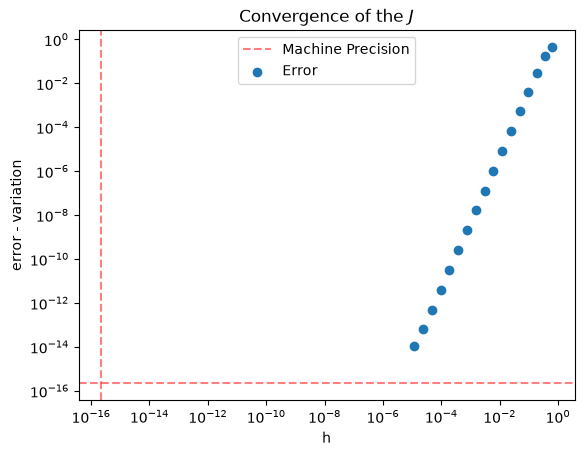

In [24]:
machine_precision = np.finfo(float).eps
Nu = 2**np.arange(2, 20) + 1
J = np.zeros(len(Nu))
L = np.abs(root[i][0]- root[i][1]) # legnth of interval
for k,N in enumerate(Nu):
    uj= np.linspace(0, np.pi, N)
    qj = q(uj,root[i][0], root[i][1])
    pj = p(qj, H[i])  
    du = uj[1]-uj[0]
    integrand_J = np.sin(uj)*pj

    J[k] = 1/np.pi*(root[i][1]-root[i][0])/2*simpson(integrand_J,du)

plt.axhline(machine_precision, color='r', alpha=0.5, linestyle='--', label='Machine Precision')
plt.axvline(machine_precision, color='r', alpha=0.5, linestyle='--')
plt.scatter(L/Nu[:-1], np.abs(J[:-1]-J[1:]), label='Error')
plt.xlabel('h')
plt.ylabel('error - variation')
plt.xscale('log')
plt.yscale('log')
plt.title('Convergence of the $J$')
plt.legend()
plt.show()


<>:21: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:21: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
C:\Users\Utente\AppData\Local\Temp\ipykernel_5424\2116801332.py:21: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
  plt.title('Convergence of $\Phi$')
C:\Users\Utente\AppData\Local\Temp\ipykernel_5424\2116801332.py:10: RuntimeWarning: divide by zero encountered in divide
  integrand_Phi = (np.sin(uj)/pj )[2:-2]


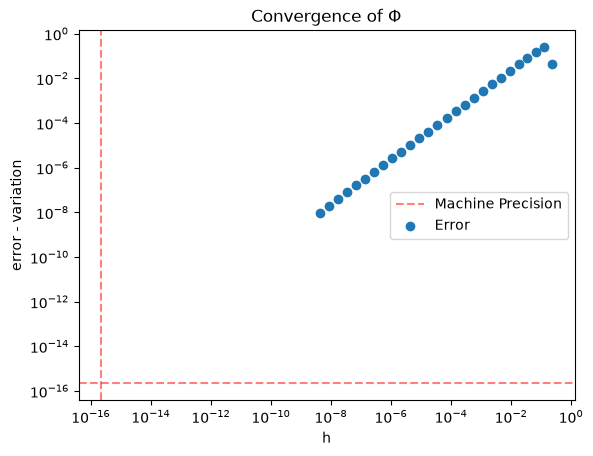

In [20]:
machine_precision = np.finfo(float).eps
Nu = 2**np.arange(2, 20) + 1
Phi = np.zeros(len(Nu))
L = np.abs(root[i][0]- root[i][1]) # legnth of interval
for k,N in enumerate(Nu):
    uj= np.linspace(0, np.pi, N)
    qj = q(uj,root[i][0], root[i][1])
    pj = p(qj, H[i])  
    du = uj[1]-uj[0]
    integrand_Phi = (np.sin(uj)/pj )[2:-2]

    Phi[k] = 1/np.pi*(root[i][1]-root[i][0])/2*simpson(integrand_Phi,du)

plt.axhline(machine_precision, color='r', alpha=0.5, linestyle='--', label='Machine Precision')
plt.axvline(machine_precision, color='r', alpha=0.5, linestyle='--')
plt.scatter(L/Nu[:-1], np.abs(Phi[:-1]-Phi[1:]), label='Error')
plt.xlabel('h')
plt.ylabel('error - variation')
plt.xscale('log')
plt.yscale('log')
plt.title('Convergence of $\Phi$')
plt.legend()
plt.show()


### 4. Label orbits
- an orbit is defined by an index i
- an orbit has associated the values of two consecutive turning points
<i> Corollario: the separatrix has one o-point (out of the domain), and two trajectories
</i>

In [377]:
orbit_root = []
orbit_label = []
orbit_energy = []
d_H = []
k = 0 
# k is the label of the orbit
dx = x[1]-x[0]

for i,qs in enumerate(root):
    # i is the index of energy level
    d = 0
    # degeneracy levels
    for j, qi in enumerate(qs[:-1]):
        # j is the index of momentum root
        if V(qi+dx) < H[i]:
            orbit_root.append(np.array([qs[j], qs[j+1]]))
            orbit_energy.append(H[i])
            orbit_label.append(k)
            k += 1
            d += 1
    d_H.append(d)

orbit_root = np.array(orbit_root)
orbit_energy = np.array(orbit_energy)
orbit_label = np.array(orbit_label)
d_H = np.array(d_H)

orbits =pd.DataFrame({'Energy': orbit_energy, 'q0': orbit_root[:,0], 'q1': orbit_root[:,1]})
orbits

,Energy,q0,q1
0,0.010101,-1.068707,-0.926211
1,0.010101,0.926211,1.068707
2,0.020202,-1.095905,-0.893864
3,0.020202,0.893864,1.095905
4,0.030303,-1.116326,-0.868226
...,...,...,...
143,0.959596,-1.544458,1.544458
144,0.969697,-1.546810,1.546810
145,0.979798,-1.549147,1.549147
146,0.989899,-1.551468,1.551468


### 5. Divide into sparatrix regions
- potential minimum are o-points
- potential maximum are x-points

In [378]:
def potential_root(V, qmin=-5, qmax=5, Nq=111):
    tol = 1e-6
    # find the roots for each energy values
    f = lambda q: (V(q+tol) - V(q-tol))/(2*tol)
    guess = np.array(root_guess(f, qmin, qmax, 111))
    # find the root with newton
    for j in range(len(guess)):
        guess[j]  = Newton_root(f, guess[j])
    guess =  guess[~np.isnan(guess)]  # Remove the root if it is not valid

    kind = []
    for xi in guess:
        if V(xi) > V(xi-2*tol):
            kind.append('max')
        elif V(xi) < V(xi-2*tol):
            kind.append('min')
        else:
            raise ValueError("The point is neither a maximum nor a minimum.")
    return np.array(guess), np.array(kind)

In [379]:
guess, kind = potential_root(V)

import pandas as pd

stationary = pd.DataFrame({'min/max': kind, 'position': guess})
stationary['V'] = V(stationary.position)
stationary['kind'] = stationary['min/max'].replace({'min': 'O', 'max':'X'})
stationary

,min/max,position,V,kind
0,min,-1.0,0.0,O
1,max,0.0,0.5,X
2,min,1.0,0.0,O


In [380]:
label = stationary['V'][stationary['kind']=='X'].value_counts()
label.loc[0] = 0
label[float('inf')] = 0
label = label.sort_index()
alphabeth = np.arange(-1, 20, dtype='int')
dict = pd.Series({label.index[i]: alphabeth[label.size -1 - i] for i in range(label.size)}, dtype=int)
stationary['isep'] = pd.cut(stationary['V'], bins=dict.index, labels=dict.values[:-1],  right=False)
orbits['isep'] = pd.cut(orbits['Energy'], bins=dict.index, labels=dict.values[:-1],  right=False)


In [381]:
# identify the regions using the separatrix points
 
separ = stationary['position'][stationary['kind']=='X']

Vs = pd.Series(V(separ.values)).value_counts().index
pos = turning_points(V, Vs)
orbits['lobe'] = 'a'
for i,xi in enumerate(pos):
    alphabeth = np.array(['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j'])
    dict = pd.Series({xi[j] : alphabeth[j] for j in range(len(xi))})
    orbits.loc[orbits['isep']==len(pos)-i, 'lobe'] = pd.cut(orbits.loc[orbits['isep']==len(pos)-i, 'q0'], bins=dict.index, labels=dict.values[:-1],  right=False)


In [ ]:
orbits

,Energy,q0,q1,isep,lobe
0,0.010101,-1.068707,-0.926211,1,a
1,0.010101,0.926211,1.068707,1,b
2,0.020202,-1.095905,-0.893864,1,a
3,0.020202,0.893864,1.095905,1,b
4,0.030303,-1.116326,-0.868226,1,a
...,...,...,...,...,...
143,0.959596,-1.544458,1.544458,0,a
144,0.969697,-1.546810,1.546810,0,a
145,0.979798,-1.549147,1.549147,0,a
146,0.989899,-1.551468,1.551468,0,a


### 6. Compute $J$ and $\omega$

- compute J with simpson rule using q as integration variable


In [ ]:
def J( Energy, q0, q1, Nu = 1000001):
    uj = np.linspace(0, np.pi, Nu)
    du = uj[1]-uj[0]

    qj = q(uj,q0, q1)
    pj = p(qj, Energy)
    integrand_J = np.sin(uj)*pj

    Action = 1/np.pi*(q1-q0)/2*simpson(integrand_J,du)
    return Action


In [384]:
orbits['J'] = orbits.apply(lambda row: J(row['Energy'],row['q0'], row['q1']), axis=1)

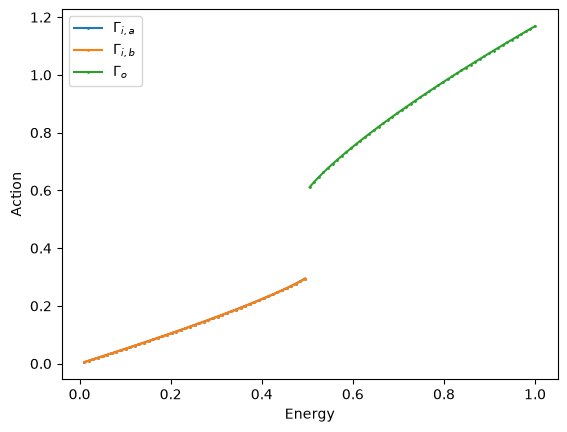

In [399]:
fig, ax = plt.subplots()


condition = (orbits['isep']==1) & (orbits['lobe'] =='a')
orbits[condition].plot(x='Energy', y='J', kind='line', marker='o',    # Draws the points ('o' for circles)
    markersize=1, label=f'$\\Gamma_{{i,a}}$', ax=ax)

condition = (orbits['isep']==1) & (orbits['lobe'] =='b')
orbits[condition].plot(x='Energy', y='J', kind='line',  marker='o',    # Draws the points ('o' for circles)
    markersize=1, label=f'$\\Gamma_{{i,b}}$', ax=ax)

condition = (orbits['isep']==0)
orbits[condition].plot(x='Energy', y='J', kind='line',  marker='o',    # Draws the points ('o' for circles)
    markersize=1, label=f'$\\Gamma_o$', ax=ax)
plt.ylabel('Action')
plt.show()

- compute $\omega = dJ/dE$ using finite difference method